In [48]:
import PyPDF2
pdf_path = "/Users/lucasplobner/Downloads/Programme-nouveaufrontpopulaire.pdf"
#-------------
nlp = spacy.load('fr_core_news_sm')
# Load the image of France map
france_mask = np.array(Image.open("france_map.png"))
#-------------
import feedparser
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import spacy
from PIL import Image
import numpy as np
import re
import unicodedata
import networkx as nx

In [51]:
def extract_text_from_pdf(pdf_path):
    text = ""
    
    try:
        with open(pdf_path, "rb") as pdf_file:
            pdf_reader = PyPDF2.PdfReader(pdf_file)

            for page_num in range(len(pdf_reader.pages)):
                page = pdf_reader.pages[page_num]
                text += page.extract_text()

    except Exception as e:
        print(f"Error: {e}")

    return text

def remove_accents(text):
    return ''.join(c for c in unicodedata.normalize('NFKD', text) if not unicodedata.combining(c))

def filter_nouns(text):
    # Remove special characters and digits (but not numbers) from the text
    text = re.sub(r'(\w+)-\s+(\w+)',r'\1\2', text)
    text = re.sub(r'\b\w\b','', text)
    text = re.sub(r'\bEn direct\b','', text)
    text = re.sub(r'[^a-zA-Z0-9À-ÿ\s]', ' ', text)
    text = remove_accents(text)

    # Filter out only common nouns from the text
    doc = nlp(text.lower())

    nouns = [token.text for token in doc if token.pos_ in ['NOUN', 'PROPN', 'ADJ', 'VERB']]
    #nouns = [token.text for token in doc if token.pos_ == 'NOUN']
    return ' '.join(nouns)

In [50]:
# Example usage
extracted_text = extract_text_from_pdf(pdf_path)
#print(extracted_text)
extracted_text_filtered = print(filter_nouns(extracted_text))

contrat legislaturele nouveau populaire rassemble femmes hommes issus organisations politiques syndicales associatives citoyennes construire programme rupture politique emmanuel macron repondant urgences sociales ecologiques democratiques paix combattons projet raciste casse sociale extreme droite voulons empecher arriver pouvoir refusons attaques libertes democratiques repression vis forces sociales associatives particulierement bafouees dernieres annees luttons multiplication discours haine proliferation menaces violences abiment democratie est majorite parlementaires engagent porter principes ethiques long mandature refusant diffusion fausses informations calomnie cyberharcelement incitations haine compris internet donnant majorite deputes nouveau front populaire francaises francais ecriront nouvelle page histoire france juin juillet votez nouveau front populaire preambule3 nouveau populaire contrat legislaturepartie premiers jours rupture seule priorite gouvernement nouveau populai

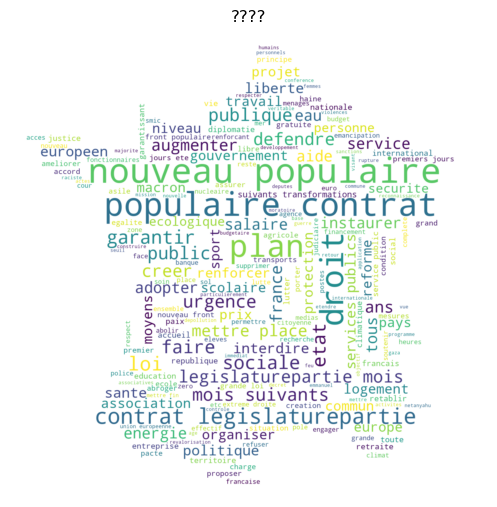

In [52]:
def generate_word_cloud(text, color):
    # Generate a word cloud with a specific colormap
    #wordcloud = WordCloud(width=800, height=400, background_color='white', colormap=colormap).generate(text)
    wordcloud = WordCloud(width=800, height=400, background_color='white', mask=france_mask).generate(text)

    return wordcloud

def display_word_clouds(wordcloud):
    # Display the word clouds using matplotlib
    plt.figure(figsize=(20, 10))
    plt.subplot(2, 3, 1)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title('????')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    wordclouds = {}
    
    extracted_text = extract_text_from_pdf(pdf_path)
    extracted_text_filtered = filter_nouns(extracted_text)
    
    # Ensure there is at least one word to generate the word cloud
    if extracted_text_filtered.strip():
        # Generate the word cloud with the specified color
        wordcloud = generate_word_cloud(extracted_text_filtered, 'Greens')

    # Display the word clouds
    display_word_clouds(wordcloud)

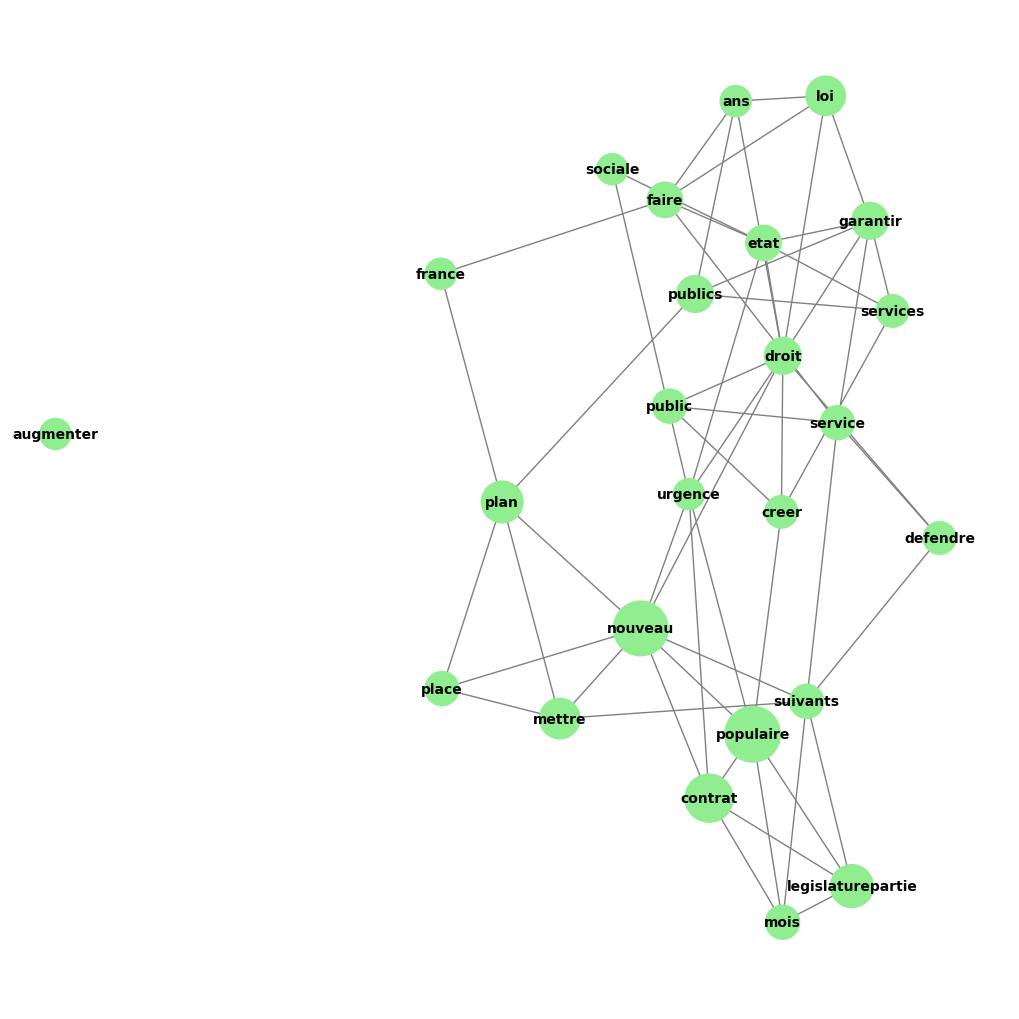

In [53]:
def build_word_graph(filtered_texts, max_words=50, window_size=3):
    """
    Build a word graph from filtered texts, linking words that appear close to each other.

    Args:
    - filtered_texts (dict): A dictionary where keys are source names and values are filtered texts.
    - max_words (int): Maximum number of words to include in the graph.
    - window_size (int): Number of words apart to consider linking.

    Returns:
    - networkx.Graph: A graph where nodes are words and edges represent proximity in text.
    """
    
    # Ensure filtered_texts is a dictionary
    if isinstance(filtered_texts, str):
        filtered_texts = {"default": filtered_texts}
    elif not isinstance(filtered_texts, dict):
        raise ValueError("filtered_texts should be a dictionary or a string")
        
    combined_text = ' '.join(filtered_texts.values())
    words = combined_text.split()
    
    # Count word frequencies
    word_freq = {}
    for word in words:
        word_freq[word] = word_freq.get(word, 0) + 1

    # Sort words by frequency and keep the top `max_words`
    sorted_words = sorted(word_freq.items(), key=lambda item: item[1], reverse=True)[:max_words]
    top_words = {word for word, freq in sorted_words}

    # Build the graph
    G = nx.Graph()
    for word in top_words:
        G.add_node(word, size=word_freq[word])

    # Add edges based on proximity in text, but not self-loops
    for i in range(len(words) - window_size):
        if words[i] in top_words:
            for j in range(1, window_size):
                if words[i + j] in top_words and words[i] != words[i + j]:
                    G.add_edge(words[i], words[i + j])

    return G

def display_word_graph(G):
    # Display the word graph using matplotlib
    plt.figure(figsize=(10, 10))
    
    # Calculate positions with the spring layout, prioritizing higher frequency words at the center
    pos = nx.spring_layout(G, k=0.5, weight=None, iterations=50, seed=42)
    
    # Draw nodes with sizes based on word frequencies
    node_sizes = [G.nodes[node]['size'] * 50 for node in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', edge_color='gray', node_size=node_sizes, font_size=10, font_weight='bold')
    
    plt.show()
    
    
if __name__ == "__main__":
    filtered_texts = {}

    extracted_text = extract_text_from_pdf(pdf_path)
    extracted_text_filtered = filter_nouns(extracted_text)

    # Build and display the word graph
    word_graph = build_word_graph(extracted_text_filtered, max_words=25, window_size=3)
    display_word_graph(word_graph)